In [120]:
#pandas to read the csv
import pandas as pd

#import pathlib to manage file paths
import pathlib

#for plotting
import matplotlib.pyplot as plt

#for model fit and statistics
import statsmodels.formula.api as smf

#geopandas to read geopackages
import geopandas as gpd

#import regex
import re

import matplotlib.patheffects as pe

import numpy as np

import libpysal
from esda.moran import Moran

import spreg




In [2]:
#set notebook path
NOTEBOOK_PATH = pathlib.Path().resolve()

#set the input data directory
Data_Directory = NOTEBOOK_PATH / "data"

#set the output data directory
Output_Directory = NOTEBOOK_PATH / "outputs"


#get a list of filepaths from the input directory
filepaths = list( (Data_Directory/"fingertips_gp_screening_data").rglob("*.csv"))

#get a list of filenames from the filepaths using pathlib
filenames = [x.name for x in filepaths]

print(filenames)

['indicators-GPs.data (1).csv', 'indicators-GPs.data (2).csv', 'indicators-GPs.data (3).csv', 'indicators-GPs.data (4).csv', 'indicators-GPs.data (5).csv', 'indicators-GPs.data (6).csv', 'indicators-GPs.data (7).csv', 'indicators-GPs.data (8).csv', 'indicators-GPs.data (9).csv', 'indicators-GPs.data.csv']


In [3]:
#empty list to store the files
gp_files = []

#read the files and store them into a list
for filepath in filepaths:
    gp_files.append(pd.read_csv(filepath, sep = ",", low_memory=False))

#concatenate all the files to get one list of gm practices
data = pd.concat(gp_files, ignore_index=True, axis=0)

data.head()

,Indicator ID,Indicator Name,Parent Code,Parent Name,Area Code,Area Name,Area Type,Sex,Age,Category Type,...,Count,Denominator,Value note,Recent Trend,Compared to England value or percentiles,Compared to ICB sub-locations value or percentiles,Time period Sortable,New data,Compared to goal,Time period range
0,91337,New cancer cases (Crude incidence rate),NaN,NaN,E92000001,England,England,Persons,All ages,NaN,...,265226.0,54759224.0,NaN,NaN,Not compared,Not compared,20090000,NaN,NaN,1y
1,91337,New cancer cases (Crude incidence rate),E92000001,England,E38000024,Greater Manchester ICB - 00V,ICB sub-locations,Persons,All ages,NaN,...,1044.0,191880.0,NaN,NaN,Not compared,Not compared,20090000,NaN,NaN,1y
2,91337,New cancer cases (Crude incidence rate),E38000024,Greater Manchester ICB - 00V,P83001,Fairfax Group Practice,GPs,Persons,All ages,NaN,...,49.0,9652.0,NaN,NaN,Similar,Similar,20090000,NaN,NaN,1y
3,91337,New cancer cases (Crude incidence rate),E38000024,Greater Manchester ICB - 00V,P83004,The Uplands Medical Practice,GPs,Persons,All ages,NaN,...,45.0,8258.0,NaN,NaN,Similar,Similar,20090000,NaN,NaN,1y
4,91337,New cancer cases (Crude incidence rate),E38000024,Greater Manchester ICB - 00V,P83005,Townside Surgery,GPs,Persons,All ages,NaN,...,25.0,5834.0,NaN,NaN,Similar,Similar,20090000,NaN,NaN,1y


In [4]:
#to find the relevant indicator IDs
data[["Indicator ID", "Indicator Name"]].drop_duplicates()

,Indicator ID,Indicator Name
0,91337,New cancer cases (Crude incidence rate)
401,92600,Bowel cancer screening coverage: aged 60 to 74...
725,92605,Urgent suspected cancer referrals (Indirectly ...
1043,92608,Urgent suspected cancer referrals resulting in...
1361,92609,New cancer cases treated resulting from an urg...
1679,93468,Proportion of GP registered populations by age...
4267,93725,Cervical screening coverage: aged 25 to 49 yea...
4672,93726,Cervical screening coverage: aged 50 to 64 yea...
5077,94063,Breast screening coverage: aged 53 to 70 years...
5158,94240,Deprivation score (IMD 2025)


In [5]:
#filter only the data for GPs with the relevant indicators
breast_cancer_data = data.loc[(data["Area Type"] == "GPs") & (data["Indicator ID"].isin([94063, 94240, 91340]))]

In [6]:
breast_cancer_data.to_csv(Output_Directory/"gm_practice_screening.csv", index = False)

In [7]:
#check the time periods to know the latest data per indicator
breast_cancer_data[["Indicator Name","Time period"]].drop_duplicates()

,Indicator Name,Time period
5079,Breast screening coverage: aged 53 to 70 years...,2022/23
5106,Breast screening coverage: aged 53 to 70 years...,2023/24
5133,Breast screening coverage: aged 53 to 70 years...,2024/25
5159,Deprivation score (IMD 2025),2025
5876,Breast screening uptake: aged 50 to 70 years old,2009/10
5903,Breast screening uptake: aged 50 to 70 years old,2010/11
5930,Breast screening uptake: aged 50 to 70 years old,2011/12
5957,Breast screening uptake: aged 50 to 70 years old,2012/13
5984,Breast screening uptake: aged 50 to 70 years old,2013/14
6011,Breast screening uptake: aged 50 to 70 years old,2014/15


In [8]:
#latest data for the indicators
breast_cancer_data_2425 = breast_cancer_data.loc[breast_cancer_data["Time period"].isin(["2024/25", "2025"])]

In [9]:
breast_cancer_data_2425.to_csv(Output_Directory/"gm_practice_screening_2425.csv", index = False)
len(breast_cancer_data_2425 )

1202

In [10]:
breast_cancer_data_2425["Indicator ID"].value_counts()

Indicator ID
94063    406
94240    405
91340    391
Name: count, dtype: int64

In [11]:
#pivot the table to get the gp wise screening data for gm
gp_wise_data = breast_cancer_data_2425.pivot(index=["Area Code", "Area Name", "Parent Name"], columns= "Indicator ID", values=["Value", "Count", "Denominator"])

In [12]:
gp_wise_data.head()

Value  \
Indicator ID                                                          91340   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   59.090909   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   60.000000   
P82003    Kildonan House           Greater Manchester ICB - 00T   68.888889   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   53.571429   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   66.666667   

                                                                             \
Indicator ID                                                          94063   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   74.449339   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   64.084507   
P82003    Kildonan House           Greater Manchester ICB - 00T   76.271186   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   66.666667   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   76.795580   

                                                                          \
Indicator ID                                                       94240   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   37.805   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   40.686   
P82003    Kildonan House           Greater Manchester ICB - 00T   19.422   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   41.867   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   18.978   

                                                                  Count  \
Indicator ID                                                      91340   
Area Code Area Name                Parent Name                            
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    65.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    60.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   155.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    75.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    80.0   

                                                                          \
Indicator ID                                                       94063   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    845.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    455.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   1350.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    540.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    695.0   

                                                                        \
Indicator ID                                                     94240   
Area Code Area Name                Parent Name                           
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    NaN   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    NaN   
P82003    Kildonan House           Greater Manchester ICB - 00T    NaN   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    NaN   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    NaN   

                                                                 Denominator  \
Indicator ID                                                           91340   
Area Code Area Name                Parent Name                                 
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T        110.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T        1

In [13]:
gp_wise_data = gp_wise_data.drop(columns =[("Count",94240), ("Denominator", 94240)])

In [14]:
gp_wise_data.head()

Value  \
Indicator ID                                                          91340   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   59.090909   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   60.000000   
P82003    Kildonan House           Greater Manchester ICB - 00T   68.888889   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   53.571429   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   66.666667   

                                                                             \
Indicator ID                                                          94063   
Area Code Area Name                Parent Name                                
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   74.449339   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   64.084507   
P82003    Kildonan House           Greater Manchester ICB - 00T   76.271186   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   66.666667   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   76.795580   

                                                                          \
Indicator ID                                                       94240   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   37.805   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T   40.686   
P82003    Kildonan House           Greater Manchester ICB - 00T   19.422   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T   41.867   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T   18.978   

                                                                  Count  \
Indicator ID                                                      91340   
Area Code Area Name                Parent Name                            
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    65.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    60.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   155.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    75.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    80.0   

                                                                          \
Indicator ID                                                       94063   
Area Code Area Name                Parent Name                             
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T    845.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T    455.0   
P82003    Kildonan House           Greater Manchester ICB - 00T   1350.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T    540.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T    695.0   

                                                                 Denominator  \
Indicator ID                                                           91340   
Area Code Area Name                Parent Name                                 
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T        110.0   
P82002    Pikes Lane 1             Greater Manchester ICB - 00T        100.0   
P82003    Kildonan House           Greater Manchester ICB - 00T        225.0   
P82004    Swan Lane Medical Centre Greater Manchester ICB - 00T        140.0   
P82005    Stable Fold Surgery      Greater Manchester ICB - 00T        120.0   

                                                                          
Indicator ID                                                       94063  
Area Code Area Name                Parent Name                            
P82001    The Dunstan Partnership  Greater Manchester ICB - 00T   1135.0  
P82002    Pikes Lane 1             Greater M

In [15]:
gp_wise_data.columns

MultiIndex([(      'Value', 91340),
            (      'Value', 94063),
            (      'Value', 94240),
            (      'Count', 91340),
            (      'Count', 94063),
            ('Denominator', 91340),
            ('Denominator', 94063)],
           names=[None, 'Indicator ID'])

In [16]:
#rename the columns
gp_wise_data.columns = ["uptake_pct", "coverage_pct", "depr_score", "uptake_count", "coverage_count", "uptake_denominator", "coverage_denominator"]

In [17]:
gp_wise_data = gp_wise_data.reset_index()
gp_wise_data.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0


In [18]:
#strip the leading and trailing white spaces for later
for col in ["Area Code", "Area Name", "Parent Name"]:
       gp_wise_data[col] = gp_wise_data[col].str.strip()

In [19]:
gp_wise_data.to_csv(Output_Directory/"gm_practice_wise_breast_cancer_data_2425.csv", index = False)

In [20]:
gp_wise_data.isna().sum()

Area Code                0
Area Name                0
Parent Name              0
uptake_pct              15
coverage_pct             0
depr_score               1
uptake_count            15
coverage_count           0
uptake_denominator      15
coverage_denominator     0
dtype: int64

There are 15 practices without an uptake percentage and 1 without a deprivation score

In [21]:
#drop the null values to plot the uptake vs deprivation
gp_wise_uptake = gp_wise_data.dropna()

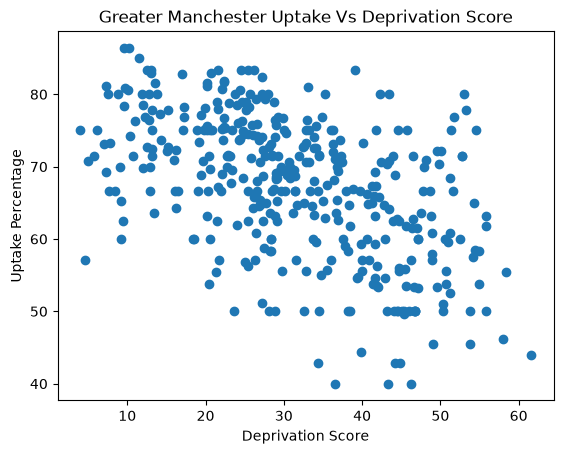

In [22]:
plt.scatter(gp_wise_uptake["depr_score"], gp_wise_uptake["uptake_pct"])
plt.xlabel("Deprivation Score"); plt.ylabel("Uptake Percentage"); plt.title("Greater Manchester Uptake Vs Deprivation Score")
plt.savefig(Output_Directory/"uptake_vs_depr.png", dpi=300, bbox_inches="tight")
plt.show()

Consistent with existing literature, screening uptake among Greater Manchester GP practices tends to decrease as deprivation increases. The scatter plot shows a clear negative association, although with considerable spread at all deprivation levels, indicating that deprivation explains only part of the variation in uptake. The spread appears wider among the most deprived practices, suggesting that factors other than deprivation may play a larger role there, with some high-deprivation practices achieving uptake comparable to the least deprived. The clustering of values at exactly 50%, 75% and 80% likely reflects small practice list sizes and should be checked before further interpretation.

In [23]:
model = smf.ols("uptake_pct ~ depr_score", data=gp_wise_uptake).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.271
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     144.7
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.50e-28
Time:                        12:34:39   Log-Likelihood:                -1383.4
No. Observations:                 391   AIC:                             2771.
Df Residuals:                     389   BIC:                             2779.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     79.7819      1.125     70.904      0.0

In [24]:
#drop the na values fron depr score column
gp_wise_coverage = gp_wise_data.dropna(subset=["depr_score"])

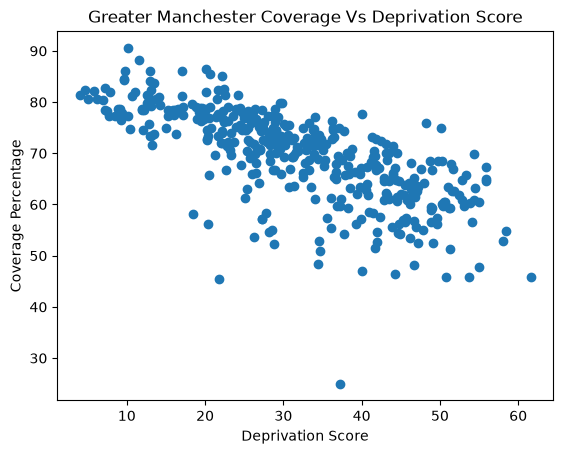

In [25]:
plt.scatter(gp_wise_coverage["depr_score"], gp_wise_coverage["coverage_pct"])
plt.xlabel("Deprivation Score"); plt.ylabel("Coverage Percentage"); plt.title("Greater Manchester Coverage Vs Deprivation Score")
plt.savefig(Output_Directory/"coverge_vs_depr.png", dpi=300, bbox_inches="tight")
plt.show()

Screening coverage among Greater Manchester GP practices shows a strong negative association with deprivation, consistent with existing literature. The relationship is tighter and more linear than that observed for uptake, likely because coverage is measured over a longer period and a larger eligible population, reducing small-number variation. Spread in coverage increases with deprivation: the least deprived practices are tightly grouped at around 75–85%, while the most deprived range from roughly 45% to 75%, suggesting that factors beyond deprivation have greater influence at the deprived end. One practice with coverage of around 25% is a clear outlier and should be checked for data quality or local circumstances before further interpretation.

In [26]:
model = smf.ols("coverage_pct ~ depr_score", data=gp_wise_coverage).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           coverage_pct   R-squared:                       0.499
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     401.6
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.77e-62
Time:                        12:34:39   Log-Likelihood:                -1324.4
No. Observations:                 405   AIC:                             2653.
Df Residuals:                     403   BIC:                             2661.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     85.3738      0.855     99.903      0.0

In [27]:
gp_wise_coverage = gp_wise_coverage.loc[gp_wise_coverage["coverage_pct"] != 25]

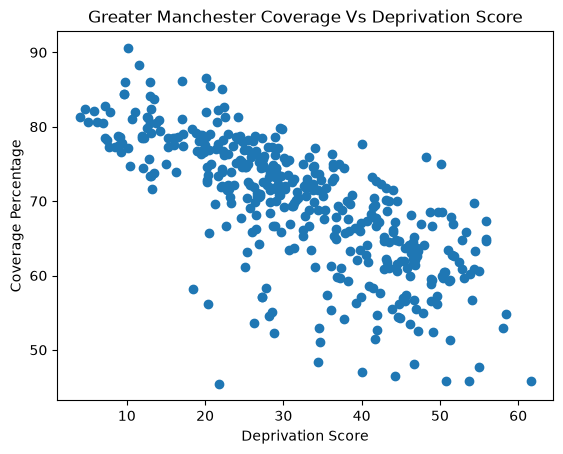

In [28]:
plt.scatter(gp_wise_coverage["depr_score"], gp_wise_coverage["coverage_pct"])
plt.xlabel("Deprivation Score"); plt.ylabel("Coverage Percentage"); plt.title("Greater Manchester Coverage Vs Deprivation Score")
plt.savefig(Output_Directory/"coverage_vs_depr_adjusted.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
model = smf.ols("coverage_pct ~ depr_score", data=gp_wise_coverage).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           coverage_pct   R-squared:                       0.523
Model:                            OLS   Adj. R-squared:                  0.522
Method:                 Least Squares   F-statistic:                     441.6
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.09e-66
Time:                        12:34:39   Log-Likelihood:                -1299.0
No. Observations:                 404   AIC:                             2602.
Df Residuals:                     402   BIC:                             2610.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     85.3640      0.809    105.525      0.0

Regression summary: deprivation vs uptake and coverage (Greater Manchester GP practices)

Simple linear regressions show that both screening uptake and coverage decline significantly with increasing deprivation (IMD score; p < 0.001 for both).

Uptake (n = 391): uptake falls by 0.40 percentage points per unit increase in deprivation score (95% CI –0.47 to –0.34), equivalent to about 4 points per 10-point increase in score. Deprivation explains 27% of the variation in uptake between practices (R² = 0.27).
Coverage (n = 405): coverage falls by 0.50 percentage points per unit increase (95% CI –0.55 to –0.45), about 5 points per 10-point increase. Deprivation explains 50% of the variation in coverage (R² = 0.50).

Across the observed range of deprivation scores (approximately 4 to 62), the fitted models imply a difference of roughly 23 percentage points in uptake and 29 points in coverage between the least and most deprived practices. The coverage gradient is somewhat steeper, and deprivation accounts for nearly twice as much of the variation in coverage as in uptake, consistent with coverage being measured over a longer window and a larger eligible population. For uptake, nearly three-quarters of the between-practice variation remains unexplained, indicating substantial influence from factors other than deprivation.

These are practice-level associations and should not be interpreted as individual-level effects.

In [30]:
#read the lsoa data
lsoas = gpd.read_file(Data_Directory/"aac0602f-d4b1-40b2-b82f-fce8b447ba0c.gdb")

C:\Users\Public\anaconda3\envs\autogis\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts.  The processing may be really slow.  You can skip the processing by setting METHOD=SKIP.
  return ogr_read(


In [31]:
#read the imd scores data
imd_scores = pd.read_excel(Data_Directory/"File_5_IoD2025_Scores_for_the_Indices_of_Deprivation.xlsx", sheet_name="IoD2025 Scores")

In [32]:
lsoas.head()

,LSOA21CD,LSOA21NM,LSOA21NMW,BNG_E,BNG_N,LAT,LONG,GlobalID,SHAPE_Length,SHAPE_Area,geometry
0,E01000001,City of London 001A,,532123,181632,51.518169,-0.097150,{86214465-5CF4-4E8F-9492-3667471C42D6},2289.743177,133759.153546,"MULTIPOLYGON (((532105.312 182010.574, 532162...."
1,E01000002,City of London 001B,,532480,181715,51.518829,-0.091970,{CD40C491-6567-405F-8C18-426E17B356CE},2486.578125,225673.949016,"MULTIPOLYGON (((532634.497 181926.016, 532619...."
2,E01000003,City of London 001C,,532239,182033,51.521740,-0.095330,{7FD27AAF-D858-4E46-9099-92B43F66B948},1142.183482,57288.376414,"MULTIPOLYGON (((532135.138 182198.131, 532158...."
3,E01000005,City of London 001E,,533581,181283,51.514690,-0.076280,{7E76A16A-028F-4F49-84B5-6E5A67322F3C},2167.942170,190508.858519,"MULTIPOLYGON (((533808.018 180767.774, 533649...."
4,E01000006,Barking and Dagenham 016A,,544994,184274,51.538750,0.089317,{25AB047E-6FCF-4F76-9176-E92E44C0E097},1935.412725,144195.364528,"MULTIPOLYGON (((545122.049 184314.931, 545271...."


In [33]:
imd_scores.head()

,LSOA code (2021),LSOA name (2021),Local Authority District code (2024),Local Authority District name (2024),Index of Multiple Deprivation (IMD) Score,Income Score (rate),Employment Score (rate),"Education, Skills and Training Score",Health Deprivation and Disability Score,Crime Score,Barriers to Housing and Services Score,Living Environment Score,Income Deprivation Affecting Children Index (IDACI) Score (rate),Income Deprivation Affecting Older People (IDAOPI) Score (rate),Children and Young People Sub-domain Score,Adult Skills Sub-domain Score,Geographical Barriers Sub-domain Score,Wider Barriers Sub-domain Score,Indoors Sub-domain Score,Outdoors Sub-domain Score
0,E01000001,City of London 001A,E09000001,City of London,8.742,0.013,0.014,0.004,-1.771,-2.220,10.950,69.345,0.039,0.012,-2.902,0.030,4.437,0.688,1.207,1.414
1,E01000002,City of London 001B,E09000001,City of London,4.722,0.018,0.010,0.169,-1.549,-2.277,6.703,43.890,0.076,0.026,-1.830,0.032,3.589,-0.628,0.355,1.839
2,E01000003,City of London 001C,E09000001,City of London,9.250,0.107,0.064,3.269,-0.292,-0.765,9.735,41.163,0.250,0.153,-0.756,0.113,2.509,0.358,0.318,1.679
3,E01000005,City of London 001E,E09000001,City of London,19.884,0.211,0.104,17.852,0.436,-0.626,24.623,38.695,0.459,0.625,-0.814,0.305,2.914,4.091,0.012,2.065
4,E01000006,Barking and Dagenham 016A,E09000002,Barking and Dagenham,25.307,0.343,0.120,25.442,-0.372,-0.072,38.025,29.616,0.640,0.156,-0.199,0.336,13.049,6.204,0.399,0.400


In [34]:
#merge the imd data to the lsoa data
lsoas_imd = lsoas.merge(imd_scores, left_on="LSOA21CD", right_on="LSOA code (2021)", how="inner")

In [35]:
#filter out the lsoas to only contain gm lsoas
mcr_lsoas = lsoas_imd.loc[lsoas_imd["Local Authority District name (2024)"].isin(["Bolton", "Bury", "Manchester", "Oldham", "Rochdale", "Salford", "Stockport", "Tameside", "Trafford", "Wigan"])]

districts = mcr_lsoas.dissolve(by="Local Authority District name (2024)")

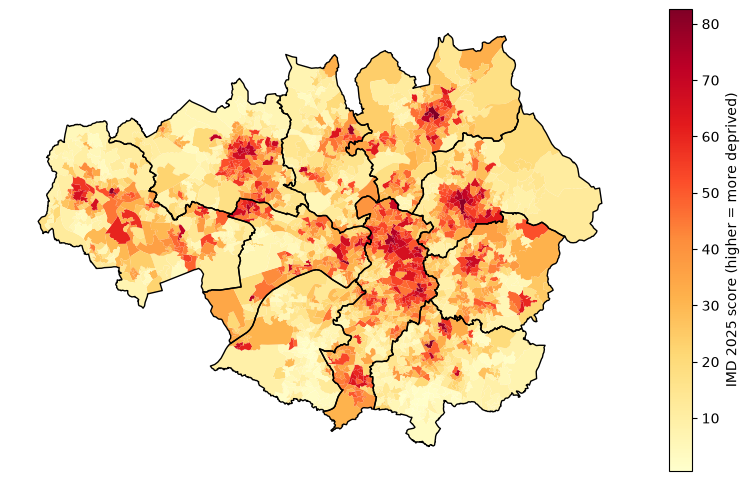

In [36]:
fig, ax = plt.subplots(figsize=(10, 10))

mcr_lsoas.plot(column="Index of Multiple Deprivation (IMD) Score", cmap="YlOrRd", legend=True, legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"}, ax=ax)
districts.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)

ax.set_axis_off()
plt.savefig(Output_Directory/"gm_lsoas_with_imd.png")
plt.show()

In [37]:
#get all the postcodes for the GPs
gp_postcodes=pd.read_csv(Data_Directory/"E92000001.addresses.csv", sep = ",")

In [38]:
gp_postcodes.head()

,Code,Name,Address,Postcode
0,A81001,The Densham Surgery,"The Health Centre, Lawson Street, Stockton-On-...",TS18 1HU
1,A81002,Queens Park Medical Centre,"Queens Park Medical Ctr, Farrer Street, Stockt...",TS18 2AW
2,A81004,Acklam Medical Centre,"Trimdon Avenue, Acklam, Middlesbrough, Cleveland",TS5 8SB
3,A81005,Springwood Surgery,"Rectory Lane, Guisborough",TS14 7DJ
4,A81006,Tennant Street Medical Practice,"Tennant St Medical Pract, Farrer Street, Stock...",TS18 2AT


In [39]:
#merge the post code data onto the gp wise screening data
mcr_gp_postcodes= gp_wise_data.merge(gp_postcodes, left_on="Area Code", right_on="Code", how="left")

In [40]:
len(mcr_gp_postcodes)

406

In [41]:
mcr_gp_postcodes.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator,Code,Name,Address,Postcode
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0,P82001,The Dunstan Partnership,"Breightmet Health Centre, Breightmet Fold Lane...",BL2 6NT
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0,P82002,Pikes Lane 1,"The Pikes Lane Centre, Deane Road, Bolton, Lan...",BL3 5HP
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0,P82003,Kildonan House,"Ramsbottom Road, Horwich, Bolton",BL6 5NW
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0,P82004,Swan Lane Medical Centre,"Swan Lane, Bolton, Lancashire",BL3 6TL
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0,P82005,Stable Fold Surgery,"119 Church Street, Westhoughton, Bolton",BL5 3SF


In [42]:
mcr_gp_postcodes["Postcode"].nunique()

340

In [43]:
# Extract postcode areas (leading letters) from the practice postcodes
areas = (
    mcr_gp_postcodes["Postcode"]
    .str.upper()
    .str.extract(r"^([A-Z]+)")[0]   # [0] selects the captured column
    .unique()
    .tolist()
)
print(areas)


['BL', 'M', 'OL', 'SK', 'WA', 'WN']


In [44]:
#get a list of post code filepaths from the input directory
pc_filepaths = list((Data_Directory/"PostCodes").rglob("ONSPD_FEB_2026_UK_*.csv"))

# Keep only the ONSPD files whose area code matches exactly
area_files = [p for p in pc_filepaths if p.stem.split("_")[-1] in areas]
print([p.name for p in area_files])

['ONSPD_FEB_2026_UK_BL.csv', 'ONSPD_FEB_2026_UK_M.csv', 'ONSPD_FEB_2026_UK_OL.csv', 'ONSPD_FEB_2026_UK_SK.csv', 'ONSPD_FEB_2026_UK_WA.csv', 'ONSPD_FEB_2026_UK_WN.csv']


In [45]:
#Check the column names in one file
print(pd.read_csv(area_files[0], nrows=5).columns.tolist())

['pcd7', 'pcd8', 'pcds', 'dointr', 'doterm', 'cty25cd', 'ced25cd', 'lad25cd', 'wd25cd', 'parncp25cd', 'usrtypind', 'east1m', 'north1m', 'gridind', 'hlth19cd', 'nhser24cd', 'ctry25cd', 'rgn25cd', 'ssr95cd', 'pcon24cd', 'eer20cd', 'educ23cd', 'ttwa15cd', 'pco19cd', 'itl25cd', 'wdstl05cd', 'oa01cd', 'wdcas03cd', 'npark16cd', 'lsoa01cd', 'msoa01cd', 'ruc01ind', 'oac01ind', 'oa11cd', 'lsoa11cd', 'msoa11cd', 'wz11cd', 'sicbl24cd', 'bua24cd', 'ruc11ind', 'oac11ind', 'lat', 'long', 'lep21cd1', 'lep21cd2', 'pfa23cd', 'imd20ind', 'cal24cd', 'icb23cd', 'oa21cd', 'lsoa21cd', 'msoa21cd', 'ruc21ind']


In [46]:
cols = ["pcds", "east1m", "north1m", "lsoa21cd", "doterm"]
onspd = pd.concat(
    [pd.read_csv(p, usecols=cols, low_memory=False) for p in area_files],
    ignore_index=True,)

In [47]:
mcr_gp_postcodes["pc_key"] = mcr_gp_postcodes["Postcode"].str.upper().str.replace(" ", "", regex=False)
onspd["pc_key"] = onspd["pcds"].str.upper().str.replace(" ", "", regex=False)

In [48]:
# Merge coordinates onto the practices
gp_coords = mcr_gp_postcodes.merge(onspd, on="pc_key", how="left")

In [49]:
print(len(gp_coords))                       
print(gp_coords["east1m"].isna().sum()) 

406
0


In [50]:
gp_points = gpd.GeoDataFrame(
    gp_coords,
    geometry=gpd.points_from_xy(gp_coords["east1m"], gp_coords["north1m"]),
    crs="EPSG:27700",
)

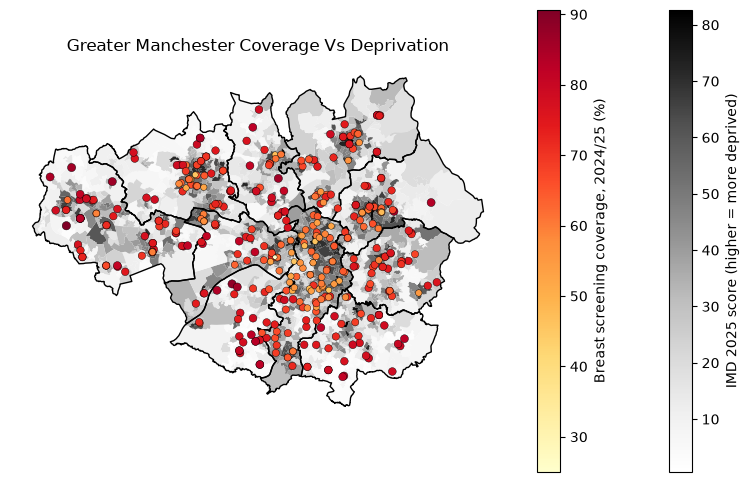

In [51]:
fig, ax = plt.subplots(figsize=(10, 10))

mcr_lsoas.plot(column="Index of Multiple Deprivation (IMD) Score", cmap="Greys", legend=True, legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"}, ax=ax)
districts.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)
gp_points.plot(ax=ax, column="coverage_pct", cmap ="YlOrRd", markersize = gp_points["coverage_pct"] * 0.4, edgecolor="black", legend=True, legend_kwds={"shrink": 0.6, "label": "Breast screening coverage, 2024/25 (%)"}, linewidth=0.3)

ax.set_axis_off()
ax.set_title("Greater Manchester Coverage Vs Deprivation")
plt.savefig(Output_Directory/"gm_lsoas_with_imd_coverage.png")
plt.show()

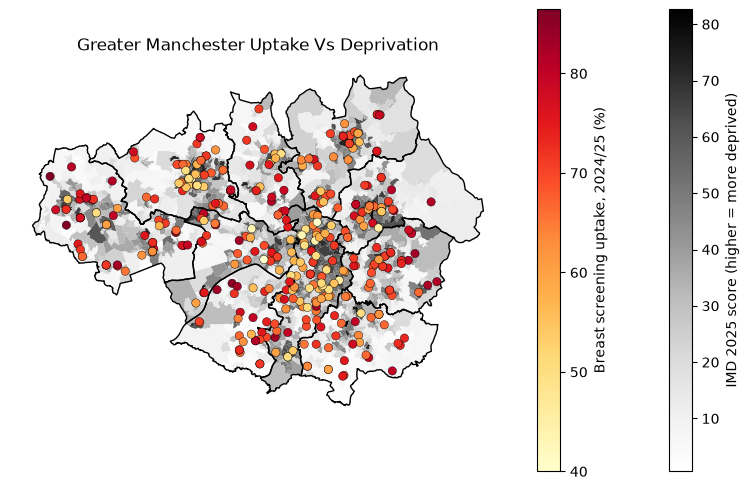

In [52]:
fig1, ax1 = plt.subplots(figsize=(10, 10))

mcr_lsoas.plot(column="Index of Multiple Deprivation (IMD) Score", cmap="Greys", legend=True, legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"}, ax=ax1)
districts.plot(ax=ax1, facecolor="none", edgecolor="black", linewidth=1)
gp_points.plot(ax=ax1, column="uptake_pct", cmap ="YlOrRd", edgecolor="black", legend=True, legend_kwds={"shrink": 0.6, "label": "Breast screening uptake, 2024/25 (%)"}, linewidth=0.3)

ax1.set_axis_off()
ax1.set_title("Greater Manchester Uptake Vs Deprivation")
plt.savefig(Output_Directory/"gm_lsoas_with_imd_uptake.png")
plt.show()

In [53]:
onspd.head()

,pcds,doterm,east1m,north1m,lsoa21cd,pc_key
0,BL0 0AA,NaN,379448.0,416851.0,E01005014,BL00AA
1,BL0 0AB,NaN,379442.0,416877.0,E01005014,BL00AB
2,BL0 0AD,NaN,379389.0,417007.0,E01005014,BL00AD
3,BL0 0AE,202205.0,379408.0,417127.0,E01005014,BL00AE
4,BL0 0AF,NaN,379415.0,418123.0,E01025357,BL00AF


In [54]:
#data for fixed breast cancer screening sites in GM
fixed_screening_sites = pd.read_csv(Data_Directory/"gm_confirmed_fixed_sites.csv", sep = ",")

In [55]:
fixed_screening_sites.head()

,site_id,site,service,borough,in_gm,postcode
0,1,Withington Community Hospital,GMBSS,Manchester,Yes,M20 2LR
1,2,Oldham Integrated Care Centre,GMBSS,Oldham,Yes,OL1 1NL
2,3,Royal Bolton Hospital Breast Unit,Bolton BSS,Bolton,Yes,BL4 0JR
3,4,Bolton One,Bolton BSS,Bolton,Yes,BL3 5BN
4,5,Radcliffe Primary Care Centre,Bolton BSS,Bury,Yes,M26 2SP


In [56]:
fixed_screening_sites["pc_key"] = fixed_screening_sites["postcode"].str.upper().str.replace(" ", "", regex=False)

In [57]:
# Merge coordinates onto the fixed screening site
fss_coords = fixed_screening_sites.merge(onspd, on="pc_key", how="left")
fss_points = gpd.GeoDataFrame(
    fss_coords,
    geometry=gpd.points_from_xy(fss_coords["east1m"], fss_coords["north1m"]),
    crs="EPSG:27700"
)

fss_coords.head()

,site_id,site,service,borough,in_gm,postcode,pc_key,pcds,doterm,east1m,north1m,lsoa21cd
0,1,Withington Community Hospital,GMBSS,Manchester,Yes,M20 2LR,M202LR,M20 2LR,NaN,383801.0,392073.0,E01005083
1,2,Oldham Integrated Care Centre,GMBSS,Oldham,Yes,OL1 1NL,OL11NL,OL1 1NL,NaN,392348.0,405249.0,E01005350
2,3,Royal Bolton Hospital Breast Unit,Bolton BSS,Bolton,Yes,BL4 0JR,BL40JR,BL4 0JR,NaN,371617.0,406456.0,E01004880
3,4,Bolton One,Bolton BSS,Bolton,Yes,BL3 5BN,BL35BN,BL3 5BN,NaN,371276.0,408680.0,E01004849
4,5,Radcliffe Primary Care Centre,Bolton BSS,Bury,Yes,M26 2SP,M262SP,M26 2SP,NaN,378660.0,407110.0,E01005008


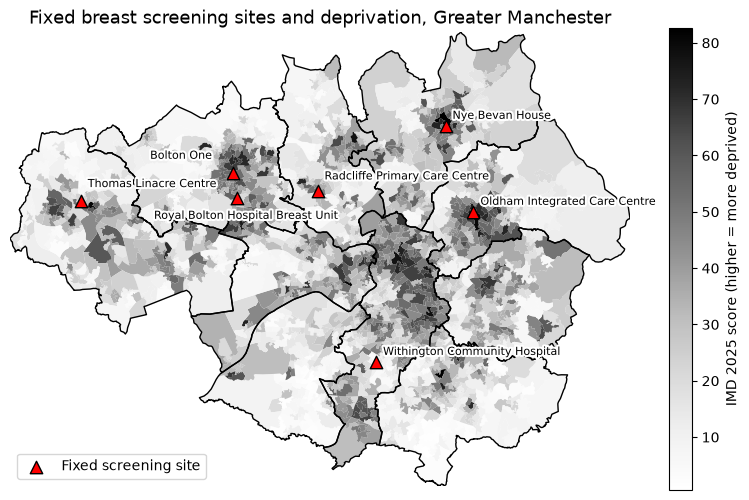

In [58]:

fig2, ax2 = plt.subplots(figsize=(10, 10))

# Layers
mcr_lsoas.plot(ax=ax2, column="Index of Multiple Deprivation (IMD) Score", cmap="Greys",
               legend=True,
               legend_kwds={"shrink": 0.6, "label": "IMD 2025 score (higher = more deprived)"})
districts.plot(ax=ax2, facecolor="none", edgecolor="black", linewidth=1)
fss_points.plot(ax=ax2, color="red", marker="^", markersize=80, edgecolor="black",
                zorder=3, label="Fixed screening site")

# Crop to Greater Manchester (hides Macclesfield)
xmin, ymin, xmax, ymax = mcr_lsoas.total_bounds
ax2.set_xlim(xmin, xmax)
ax2.set_ylim(ymin, ymax)

# Site labels, with custom offsets for the three close Bolton/Bury sites
offsets = {
    "Bolton One": (-60, 10),
    "Royal Bolton Hospital Breast Unit": (-60, -15),
    "Radcliffe Primary Care Centre": (5, 8),
    "Thomas Linacre Centre": (5, 10),
}

for _, row in fss_points.iterrows():
    offset = offsets.get(row["site"], (5, 5))
    ax2.annotate(
        row["site"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=offset, textcoords="offset points",
        fontsize=8,
        path_effects=[pe.withStroke(linewidth=3, foreground="white")],
        annotation_clip=True
    )

# Finishing
ax2.set_axis_off()
ax2.legend(loc="lower left")
ax2.set_title("Fixed breast screening sites and deprivation, Greater Manchester", fontsize=13)

plt.savefig(Output_Directory/"gm_fixed_screening_sites.png", bbox_inches="tight", dpi=300)
plt.show()

In [59]:
#read the population weighted centroids of lsoas
pwc_lsoas = gpd.read_file(Data_Directory/"f0c9921b-27ba-4550-aba8-3200c91a62f9.gdb")

In [60]:
pwc_lsoas.head()

,LSOA21CD,GlobalID,GlobalID_2,geometry
0,E01000001,38ad8fe8-682a-4533-b51a-16c9ca366294,{DD315BA1-4937-466D-8C6A-CF5D42615B0A},POINT (532181.764 181792.282)
1,E01018945,0681c038-f7dd-4a2e-83c1-c8d3b32443f6,{3AE37539-20DB-4F78-9537-61BFDDACFCE5},POINT (202699.421 65668.022)
2,E01000120,e5ffc70b-0e24-40a9-afe8-13da1ec4032e,{78BEBE76-7B81-4351-BC3B-0B3AC11CA8E5},POINT (528823.572 194238.047)
3,E01031487,17c7f13f-1a6a-45c5-a5cc-2c50e725c799,{E79A12BF-45A3-4649-B1FE-8C5A93DCA04A},POINT (486282.408 106971.914)
4,E01021013,f55e8508-e975-4025-896c-a270de41fc79,{054AFC3D-7CE7-42FE-ACF2-00789F24448B},POINT (583256.523 111412.976)


In [61]:
#filter to GM
mcr_pwc_lsoas= pwc_lsoas.loc[pwc_lsoas["LSOA21CD"].isin(mcr_lsoas["LSOA21CD"].tolist())]

In [62]:
len(mcr_pwc_lsoas)

1702

In [63]:
mcr_td_lsoa_to_screening = gpd.sjoin_nearest(
    mcr_pwc_lsoas,               # features you want a match for (each keeps its row)
    fss_points,              # features to search among
    how="left",             # keep every left row (default is "inner")
    distance_col="dist",    # name of new column holding the distance
    max_distance=None       # optional: ignore matches farther than this (CRS units)
)

In [64]:
len(mcr_td_lsoa_to_screening)

1702

In [65]:
mcr_td_lsoa_to_screening["dist_km"] = mcr_td_lsoa_to_screening["dist"] / 1000
mcr_td_lsoa_to_screening["dist_km"].describe()

count    1702.000000
mean        5.312428
std         2.720155
min         0.146623
25%         3.185278
50%         5.202282
75%         7.153572
max        14.379682
Name: dist_km, dtype: float64

In [66]:
mcr_td_lsoa_to_screening["site"].value_counts()

site
Withington Community Hospital             625
Oldham Integrated Care Centre             331
Radcliffe Primary Care Centre             228
Thomas Linacre Centre                     158
Royal Bolton Hospital Breast Unit         144
Bolton One                                107
Nye Bevan House                           105
Macclesfield District General Hospital      4
Name: count, dtype: int64

In [67]:
mcr_td_lsoa_to_screening.to_csv(Output_Directory/"gm_distance_to_fixed_screening.csv", index = False)

In [68]:
mcr_td_lsoa_to_screening.head()

,LSOA21CD,GlobalID,GlobalID_2,geometry,index_right,site_id,site,service,borough,in_gm,postcode,pc_key,pcds,doterm,east1m,north1m,lsoa21cd,dist,dist_km
13553,E01004766,f5eaab06-5fd6-4ac7-b8ac-e5d9ca9c754a,{04117FEF-A0FB-4987-A77C-374C55300114},POINT (371179.34 411529.125),3,4,Bolton One,Bolton BSS,Bolton,Yes,BL3 5BN,BL35BN,BL3 5BN,NaN,371276.0,408680.0,E01004849,2850.763796,2.850764
13554,E01005172,10a63c7e-3493-4b2e-af59-d43bb1eeede3,{D6540502-8A76-4788-AA78-C060DF4292FE},POINT (384369.955 391557.119),0,1,Withington Community Hospital,GMBSS,Manchester,Yes,M20 2LR,M202LR,M20 2LR,NaN,383801.0,392073.0,E01005083,768.012792,0.768013
13559,E01005308,de8390ec-a118-4e02-87c4-a2fdf087a35f,{B45EE8FB-F871-46BD-8E48-EB17EE3B7167},POINT (385498.459 392275.502),0,1,Withington Community Hospital,GMBSS,Manchester,Yes,M20 2LR,M202LR,M20 2LR,NaN,383801.0,392073.0,E01005083,1709.495631,1.709496
13568,E01005031,c0236804-814e-42e9-b589-c64680fe45a1,{DFF6624E-A160-4BA1-AB2B-E6689B07AEBC},POINT (380741.836 402814.32),4,5,Radcliffe Primary Care Centre,Bolton BSS,Bury,Yes,M26 2SP,M262SP,M26 2SP,NaN,378660.0,407110.0,E01005008,4773.563918,4.773564
13570,E01005353,01f74bea-fdd6-4e94-a5d9-7a1052612754,{6541AF34-29CF-4C42-93C4-438B2DB356DF},POINT (391672.711 405105.972),1,2,Oldham Integrated Care Centre,GMBSS,Oldham,Yes,OL1 1NL,OL11NL,OL1 1NL,NaN,392348.0,405249.0,E01005350,690.270281,0.690270


In [69]:
lsoa_dists = mcr_pwc_lsoas[["LSOA21CD"]].copy()   # one row per LSOA, to collect results

svc_codes = {"GMBSS": "gm", "Bolton BSS": "bolton",
             "South Lancashire BSS": "slancs", "East Cheshire & Stockport BSS": "ecs"}
#calculate the distances from each pwc to each of the screening sites from the fours services in GM
for svc in fss_points["service"].unique():
    sites_svc = fss_points[fss_points["service"] == svc]
    nearest = gpd.sjoin_nearest(mcr_pwc_lsoas, sites_svc[["site", "geometry"]],
                                how="left", distance_col="dist")
    lsoa_dists[f"dist_{svc_codes[svc]}"] = nearest["dist"].values / 1000   # km

In [70]:
lsoa_dists.head()

,LSOA21CD,dist_gm,dist_bolton,dist_slancs,dist_ecs
13553,E01004766,22.080583,2.850764,14.328061,42.354955
13554,E01005172,0.768013,16.567912,30.266700,18.721094
13559,E01005308,1.709496,16.334836,30.929198,19.061260
13568,E01005031,11.168457,4.773564,23.110882,30.544707
13570,E01005353,0.690270,7.893282,33.810351,31.187553


In [71]:
#read the female patient data for each GP
gp_female_per_lsoa = pd.read_csv(Data_Directory/"gp-reg-pat-prac-lsoa-female.csv", sep = ",", usecols = ["PRACTICE_CODE", "LSOA_CODE", "NUMBER_OF_PATIENTS"])

In [72]:
gp_female_per_lsoa.head()

,PRACTICE_CODE,LSOA_CODE,NUMBER_OF_PATIENTS
0,A81001,E01011959,4
1,A81001,E01012009,1
2,A81001,E01012023,1
3,A81001,E01012057,1
4,A81001,E01012187,3


In [73]:
#filter for GM practices
gm_gp_female_per_lsoa = gp_female_per_lsoa.loc[gp_female_per_lsoa["PRACTICE_CODE"].isin(gp_wise_data["Area Code"].tolist())]

In [74]:
len(gm_gp_female_per_lsoa)

53414

In [75]:
#Filter to include only LSOAs starting with E01 that is only England
gm_gp_female_per_lsoa = gm_gp_female_per_lsoa.loc[gm_gp_female_per_lsoa["LSOA_CODE"].str.startswith("E01")]

In [76]:
len(gm_gp_female_per_lsoa)

53003

In [77]:
gm_gp_female_per_lsoa["LSOA_CODE"].nunique()

4893

In [78]:
in_gm = gm_gp_female_per_lsoa["LSOA_CODE"].isin(mcr_lsoas["LSOA21CD"])

women_in_gm = gm_gp_female_per_lsoa.loc[in_gm, "NUMBER_OF_PATIENTS"].sum()
women_total = gm_gp_female_per_lsoa["NUMBER_OF_PATIENTS"].sum()

print(women_in_gm / women_total * 100)

98.94301906843654


In [79]:
gm_gp_female_per_lsoa["in_gm"] = gm_gp_female_per_lsoa["LSOA_CODE"].isin(mcr_lsoas["LSOA21CD"])
gm_gp_female_per_lsoa["women_in_gm"] = gm_gp_female_per_lsoa["NUMBER_OF_PATIENTS"] * gm_gp_female_per_lsoa["in_gm"]

share = gm_gp_female_per_lsoa.groupby("PRACTICE_CODE")[["women_in_gm", "NUMBER_OF_PATIENTS"]].sum()
share["pct_in_gm"] = share["women_in_gm"] / share["NUMBER_OF_PATIENTS"] * 100

share.sort_values("pct_in_gm").head(15)

,women_in_gm,NUMBER_OF_PATIENTS,pct_in_gm
PRACTICE_CODE,,,
P82034,860,1961,43.855176
P89602,1321,1916,68.945720
P88025,3856,5318,72.508462
P88623,2911,3687,78.953078
P83006,3347,4134,80.962748
P89004,2599,3154,82.403297
P86013,2504,3019,82.941371
P82643,3306,3831,86.296006
P92017,6013,6657,90.325973


In [80]:
share_with_name = share.merge(mcr_gp_postcodes[["Area Code", "Area Name"]], left_on="PRACTICE_CODE", right_on = "Area Code", how = "left")

In [81]:
share_with_name.sort_values("pct_in_gm").head(15)

,women_in_gm,NUMBER_OF_PATIENTS,pct_in_gm,Area Code,Area Name
26,860,1961,43.855176,P82034,Edgworth Medical Centre
291,1321,1916,68.945720,P89602,The Smithy Surgery
256,3856,5318,72.508462,P88025,Hulme Hall Medical Group
265,2911,3687,78.953078,P88623,High Lane Medical Centre
47,3347,4134,80.962748,P83006,Ramsbottom Medical Practice
270,2599,3154,82.403297,P89004,Awburn House Medical Practice
184,2504,3019,82.941371,P86013,Healey Surgery
41,3306,3831,86.296006,P82643,Bromley Meadows Surgery
336,6013,6657,90.325973,P92017,Shevington Surgery
322,2529,2783,90.873158,P92001,Medicentre


In [82]:
gm_gp_female_per_lsoa.head()

,PRACTICE_CODE,LSOA_CODE,NUMBER_OF_PATIENTS,in_gm,women_in_gm
724570,P82001,E01004766,2,True,2
724571,P82001,E01004767,7,True,7
724572,P82001,E01004768,8,True,8
724573,P82001,E01004769,2,True,2
724574,P82001,E01004770,8,True,8


In [83]:
#filter out patients belonging to lsoas outside GM
gm_only_gp_female_per_lsoa=gm_gp_female_per_lsoa.loc[gm_gp_female_per_lsoa["women_in_gm"] !=0]

In [84]:
gm_only_gp_female_per_lsoa["LSOA_CODE"].nunique()

1702

In [85]:
fixed_screening_sites["service"].value_counts()

service
Bolton BSS                       4
GMBSS                            2
South Lancashire BSS             1
East Cheshire & Stockport BSS    1
Name: count, dtype: int64

In [86]:
# sub-ICB code -> breast screening service
subicb_to_service = {
    "14L": "GMBSS",                          # Manchester
    "00Y": "GMBSS",                          # Oldham
    "01G": "GMBSS",                          # Salford
    "01Y": "GMBSS",                          # Tameside
    "02A": "GMBSS",                          # Trafford
    "00T": "Bolton BSS",                     # Bolton
    "00V": "Bolton BSS",                     # Bury
    "01D": "Bolton BSS",                     # Heywood, Middleton & Rochdale
    "01W": "East Cheshire & Stockport BSS",  # Stockport
    "02H": "South Lancashire BSS",           # Wigan
}

# check 1: should be 10 parent names, all GM ICB
print(gp_wise_data["Parent Name"].unique())

# extract the sub-ICB code and assign the service
gp_wise_data["subicb_code"] = gp_wise_data["Parent Name"].str[-3:]
gp_wise_data["service"] = gp_wise_data["subicb_code"].map(subicb_to_service)

# also record which distance column each practice should use
gp_wise_data["dist_col"] = "dist_" + gp_wise_data["service"].map(svc_codes)

# check 2: should be 0
print(gp_wise_data["service"].isna().sum())

# quick sanity check of counts per service
gp_wise_data["service"].value_counts()

<ArrowStringArray>
['Greater Manchester ICB - 00T', 'Greater Manchester ICB - 00V',
 'Greater Manchester ICB - 14L', 'Greater Manchester ICB - 00Y',
 'Greater Manchester ICB - 01D', 'Greater Manchester ICB - 01G',
 'Greater Manchester ICB - 01W', 'Greater Manchester ICB - 01Y',
 'Greater Manchester ICB - 02A', 'Greater Manchester ICB - 02H']
Length: 10, dtype: str
0


service
GMBSS                            209
Bolton BSS                       110
South Lancashire BSS              55
East Cheshire & Stockport BSS     32
Name: count, dtype: int64

In [87]:
gp_wise_data.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator,subicb_code,service,dist_col
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0,00T,Bolton BSS,dist_bolton
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0,00T,Bolton BSS,dist_bolton
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0,00T,Bolton BSS,dist_bolton
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0,00T,Bolton BSS,dist_bolton
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0,00T,Bolton BSS,dist_bolton


In [88]:
# reshape distances to long format: one row per LSOA per service
lsoa_dists_long = lsoa_dists.melt(
    id_vars="LSOA21CD", var_name="dist_col", value_name="dist_km")

In [89]:
lsoa_dists_long.head()

,LSOA21CD,dist_col,dist_km
0,E01004766,dist_gm,22.080583
1,E01005172,dist_gm,0.768013
2,E01005308,dist_gm,1.709496
3,E01005031,dist_gm,11.168457
4,E01005353,dist_gm,0.690270


In [90]:
# attach each practice's dist_col to its patient rows
pat = gm_only_gp_female_per_lsoa.merge(
    gp_wise_data[["Area Code", "dist_col"]],
    left_on="PRACTICE_CODE", right_on="Area Code", how="left"
)

pat.head()

,PRACTICE_CODE,LSOA_CODE,NUMBER_OF_PATIENTS,in_gm,women_in_gm,Area Code,dist_col
0,P82001,E01004766,2,True,2,P82001,dist_bolton
1,P82001,E01004767,7,True,7,P82001,dist_bolton
2,P82001,E01004768,8,True,8,P82001,dist_bolton
3,P82001,E01004769,2,True,2,P82001,dist_bolton
4,P82001,E01004770,8,True,8,P82001,dist_bolton


In [91]:
# attach the distance for that LSOA under that practice's service
pat = pat.merge(
    lsoa_dists_long,
    left_on=["LSOA_CODE", "dist_col"], right_on=["LSOA21CD", "dist_col"],
    how="left"
)
pat.head()

,PRACTICE_CODE,LSOA_CODE,NUMBER_OF_PATIENTS,in_gm,women_in_gm,Area Code,dist_col,LSOA21CD,dist_km
0,P82001,E01004766,2,True,2,P82001,dist_bolton,E01004766,2.850764
1,P82001,E01004767,7,True,7,P82001,dist_bolton,E01004767,2.869157
2,P82001,E01004768,8,True,8,P82001,dist_bolton,E01004768,4.363736
3,P82001,E01004769,2,True,2,P82001,dist_bolton,E01004769,4.199846
4,P82001,E01004770,8,True,8,P82001,dist_bolton,E01004770,3.616901


In [92]:
# checks: row count unchanged, no missing distances
print(len(gm_only_gp_female_per_lsoa), len(pat))
print(pat["dist_km"].isna().sum())


47637 47637
0


In [93]:
# weight by patients and aggregate per practice
pat["weighted_dist"] = pat["NUMBER_OF_PATIENTS"] * pat["dist_km"]

practice_dist = pat.groupby("PRACTICE_CODE").agg(
    weighted_sum=("weighted_dist", "sum"),
    gm_women=("NUMBER_OF_PATIENTS", "sum"),
)
practice_dist["mean_dist_km"] = practice_dist["weighted_sum"] / practice_dist["gm_women"]

# check: should be 406 practices, sensible range
print(len(practice_dist))
practice_dist["mean_dist_km"].describe()

406


count    406.000000
mean       6.426285
std        4.251201
min        1.120226
25%        2.962648
50%        5.566432
75%        8.462081
max       20.489348
Name: mean_dist_km, dtype: float64

In [94]:
practice_dist.head()

,weighted_sum,gm_women,mean_dist_km
PRACTICE_CODE,,,
P82001,17024.480533,5302,3.210954
P82002,6608.804962,3488,1.894726
P82003,51009.014229,7188,7.096413
P82004,6478.015533,4888,1.325290
P82005,22321.419529,3650,6.115457


In [95]:
gp_wise_data = (
    gp_wise_data
    .merge(practice_dist[["mean_dist_km"]], left_on="Area Code", right_index=True, how="left")
    .merge(share[["pct_in_gm"]], left_on="Area Code", right_index=True, how="left")
)

In [96]:
gp_wise_data.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator,subicb_code,service,dist_col,mean_dist_km,pct_in_gm
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0,00T,Bolton BSS,dist_bolton,3.210954,99.905785
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0,00T,Bolton BSS,dist_bolton,1.894726,99.628678
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0,00T,Bolton BSS,dist_bolton,7.096413,94.853523
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0,00T,Bolton BSS,dist_bolton,1.325290,99.959100
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0,00T,Bolton BSS,dist_bolton,6.115457,99.835886


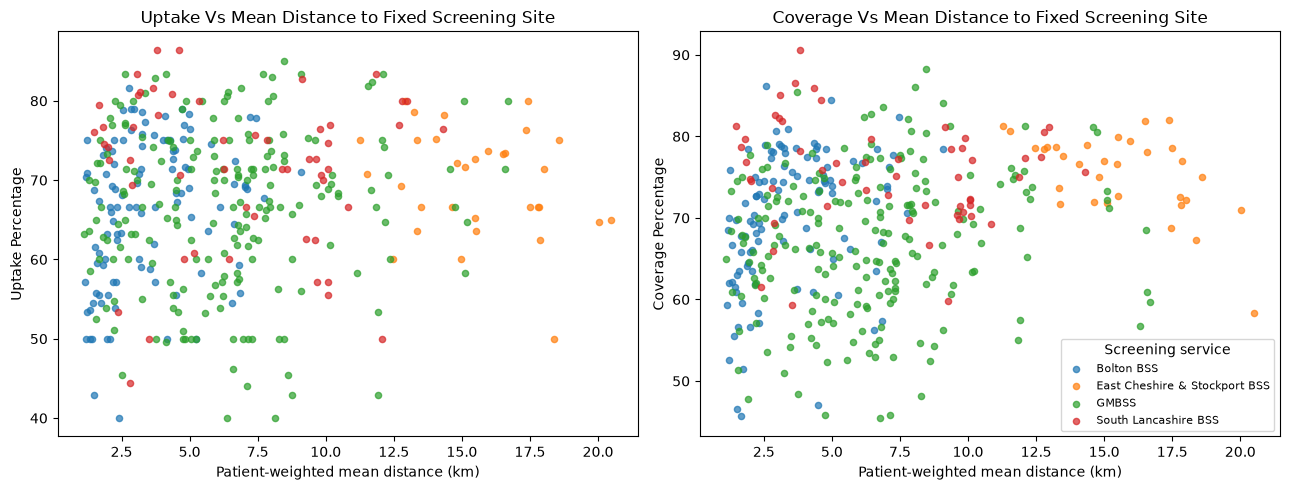

In [97]:
# drop the coverage outlier consistently with your earlier analysis
plot_data = gp_wise_data.loc[gp_wise_data["coverage_pct"] != 25]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

for svc, grp in plot_data.groupby("service"):
    axes[0].scatter(grp["mean_dist_km"], grp["uptake_pct"], label=svc, s=20, alpha=0.7)
    axes[1].scatter(grp["mean_dist_km"], grp["coverage_pct"], label=svc, s=20, alpha=0.7)

axes[0].set_ylabel("Uptake Percentage")
axes[0].set_title("Uptake Vs Mean Distance to Fixed Screening Site")
axes[1].set_ylabel("Coverage Percentage")
axes[1].set_title("Coverage Vs Mean Distance to Fixed Screening Site")

for ax in axes:
    ax.set_xlabel("Patient-weighted mean distance (km)")
axes[1].legend(title="Screening service", fontsize=8)

plt.tight_layout()
plt.savefig(Output_Directory/"uptake_coverage_vs_distance.png", dpi=300, bbox_inches="tight")
plt.show()

In [98]:
# uptake vs distance (drop practices missing uptake or distance)
uptake_dist_data = plot_data.dropna(subset=["uptake_pct", "mean_dist_km"])
model_uptake_dist = smf.ols("uptake_pct ~ mean_dist_km", data=uptake_dist_data).fit()
print(model_uptake_dist.summary())

# coverage vs distance
coverage_dist_data = plot_data.dropna(subset=["coverage_pct", "mean_dist_km"])
model_coverage_dist = smf.ols("coverage_pct ~ mean_dist_km", data=coverage_dist_data).fit()
print(model_coverage_dist.summary())

                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     5.284
Date:                Thu, 05 Nov 2026   Prob (F-statistic):             0.0221
Time:                        12:34:52   Log-Likelihood:                -1442.6
No. Observations:                 391   AIC:                             2889.
Df Residuals:                     389   BIC:                             2897.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       65.5342      0.888     73.782   

In [99]:
# same sample for every model: needs uptake/coverage, distance and deprivation
uptake_mr = plot_data.dropna(subset=["uptake_pct", "mean_dist_km", "depr_score"])
coverage_mr = plot_data.dropna(subset=["coverage_pct", "mean_dist_km", "depr_score"])

# how strongly are the two predictors related?
print("Correlation distance vs deprivation:",
      coverage_mr[["mean_dist_km", "depr_score"]].corr().iloc[0, 1])

# multiple regressions (HC3 robust standard errors)
mr_uptake = smf.ols("uptake_pct ~ mean_dist_km + depr_score", data=uptake_mr).fit(cov_type="HC3")
mr_coverage = smf.ols("coverage_pct ~ mean_dist_km + depr_score", data=coverage_mr).fit(cov_type="HC3")

print(mr_uptake.summary())
print(mr_coverage.summary())

Correlation distance vs deprivation: -0.30316671756883007
                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.271
Method:                 Least Squares   F-statistic:                     65.66
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.75e-25
Time:                        12:34:52   Log-Likelihood:                -1382.5
No. Observations:                 391   AIC:                             2771.
Df Residuals:                     388   BIC:                             2783.
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------

In [100]:
models = {
    "uptake: distance only":    smf.ols("uptake_pct ~ mean_dist_km", data=uptake_mr).fit(cov_type="HC3"),
    "uptake: deprivation only": smf.ols("uptake_pct ~ depr_score", data=uptake_mr).fit(cov_type="HC3"),
    "uptake: both":             mr_uptake,
    "coverage: distance only":    smf.ols("coverage_pct ~ mean_dist_km", data=coverage_mr).fit(cov_type="HC3"),
    "coverage: deprivation only": smf.ols("coverage_pct ~ depr_score", data=coverage_mr).fit(cov_type="HC3"),
    "coverage: both":             mr_coverage,
}

comparison = pd.DataFrame({
    name: {
        "n": int(m.nobs),
        "b_distance": m.params.get("mean_dist_km"),
        "p_distance": m.pvalues.get("mean_dist_km"),
        "b_deprivation": m.params.get("depr_score"),
        "p_deprivation": m.pvalues.get("depr_score"),
        "R2": m.rsquared,
    }
    for name, m in models.items()
}).T

comparison.round(3)

,n,b_distance,p_distance,b_deprivation,p_deprivation,R2
uptake: distance only,391.0,0.267,0.011,NaN,NaN,0.013
uptake: deprivation only,391.0,NaN,NaN,-0.401,0.0,0.271
uptake: both,391.0,-0.137,0.211,-0.415,0.0,0.274
coverage: distance only,404.0,0.391,0.000,NaN,NaN,0.036
coverage: deprivation only,404.0,NaN,NaN,-0.498,0.0,0.523
coverage: both,404.0,-0.066,0.338,-0.504,0.0,0.524


After adjusting for deprivation, patient-weighted distance to the nearest fixed screening site of the practice’s service showed no significant association with uptake (β = −0.14 pp/km, 95% CI −0.35 to 0.08, p = 0.21) or coverage (β = −0.07 pp/km, 95% CI −0.20 to 0.07, p = 0.34), and added less than 0.004 to R². The positive unadjusted association reflected confounding: practices further from fixed sites are, on average, less deprived (r = −0.30). The confidence intervals exclude effects larger than roughly 3.5 (uptake) and 2 (coverage) percentage points per 10 km. Deprivation remained the dominant predictor (uptake β = −0.42; coverage β = −0.50; both p < 0.001). Distances were straight-line and to fixed sites only; mobile screening units were not included.

In [101]:
ethnic_lsoa = pd.read_csv(Data_Directory/"census2021-ts021-lsoa.csv", sep = ",")

In [102]:
ethnic_lsoa.head()

,date,geography,geography code,Ethnic group: Total: All usual residents,"Ethnic group: Asian, Asian British or Asian Welsh","Ethnic group: Asian, Asian British or Asian Welsh: Bangladeshi","Ethnic group: Asian, Asian British or Asian Welsh: Chinese","Ethnic group: Asian, Asian British or Asian Welsh: Indian","Ethnic group: Asian, Asian British or Asian Welsh: Pakistani","Ethnic group: Asian, Asian British or Asian Welsh: Other Asian",...,Ethnic group: Mixed or Multiple ethnic groups: Other Mixed or Multiple ethnic groups,Ethnic group: White,"Ethnic group: White: English, Welsh, Scottish, Northern Irish or British",Ethnic group: White: Irish,Ethnic group: White: Gypsy or Irish Traveller,Ethnic group: White: Roma,Ethnic group: White: Other White,Ethnic group: Other ethnic group,Ethnic group: Other ethnic group: Arab,Ethnic group: Other ethnic group: Any other ethnic group
0,2021,City of London 001A,E01000001,1474,158,4,66,49,2,37,...,18,1181,822,32,0,11,316,68,22,46
1,2021,City of London 001B,E01000002,1386,181,7,102,37,3,32,...,28,1084,734,42,0,6,302,50,13,37
2,2021,City of London 001C,E01000003,1612,153,11,52,37,3,50,...,44,1195,815,33,0,4,343,107,18,89
3,2021,City of London 001E,E01000005,1101,354,263,35,24,1,31,...,32,424,255,17,0,4,148,125,24,101
4,2021,Barking and Dagenham 016A,E01000006,1845,885,214,11,163,409,88,...,26,605,241,15,0,11,338,85,3,82


In [103]:
ethnic_lsoa.columns

Index(['date', 'geography', 'geography code',
       'Ethnic group: Total: All usual residents',
       'Ethnic group: Asian, Asian British or Asian Welsh',
       'Ethnic group: Asian, Asian British or Asian Welsh: Bangladeshi',
       'Ethnic group: Asian, Asian British or Asian Welsh: Chinese',
       'Ethnic group: Asian, Asian British or Asian Welsh: Indian',
       'Ethnic group: Asian, Asian British or Asian Welsh: Pakistani',
       'Ethnic group: Asian, Asian British or Asian Welsh: Other Asian',
       'Ethnic group: Black, Black British, Black Welsh, Caribbean or African',
       'Ethnic group: Black, Black British, Black Welsh, Caribbean or African: African',
       'Ethnic group: Black, Black British, Black Welsh, Caribbean or African: Caribbean',
       'Ethnic group: Black, Black British, Black Welsh, Caribbean or African: Other Black',
       'Ethnic group: Mixed or Multiple ethnic groups',
       'Ethnic group: Mixed or Multiple ethnic groups: White and Asian',
       

In [104]:
ethnic_lsoa["non_white_pct"]= (ethnic_lsoa["Ethnic group: Total: All usual residents"] - ethnic_lsoa["Ethnic group: White: English, Welsh, Scottish, Northern Irish or British"])/ethnic_lsoa["Ethnic group: Total: All usual residents"]*100

In [105]:
ethnic_lsoa.head()

,date,geography,geography code,Ethnic group: Total: All usual residents,"Ethnic group: Asian, Asian British or Asian Welsh","Ethnic group: Asian, Asian British or Asian Welsh: Bangladeshi","Ethnic group: Asian, Asian British or Asian Welsh: Chinese","Ethnic group: Asian, Asian British or Asian Welsh: Indian","Ethnic group: Asian, Asian British or Asian Welsh: Pakistani","Ethnic group: Asian, Asian British or Asian Welsh: Other Asian",...,Ethnic group: White,"Ethnic group: White: English, Welsh, Scottish, Northern Irish or British",Ethnic group: White: Irish,Ethnic group: White: Gypsy or Irish Traveller,Ethnic group: White: Roma,Ethnic group: White: Other White,Ethnic group: Other ethnic group,Ethnic group: Other ethnic group: Arab,Ethnic group: Other ethnic group: Any other ethnic group,non_white_pct
0,2021,City of London 001A,E01000001,1474,158,4,66,49,2,37,...,1181,822,32,0,11,316,68,22,46,44.233379
1,2021,City of London 001B,E01000002,1386,181,7,102,37,3,32,...,1084,734,42,0,6,302,50,13,37,47.041847
2,2021,City of London 001C,E01000003,1612,153,11,52,37,3,50,...,1195,815,33,0,4,343,107,18,89,49.441687
3,2021,City of London 001E,E01000005,1101,354,263,35,24,1,31,...,424,255,17,0,4,148,125,24,101,76.839237
4,2021,Barking and Dagenham 016A,E01000006,1845,885,214,11,163,409,88,...,605,241,15,0,11,338,85,3,82,86.937669


In [106]:
#attach ethnicity data to patient data
# attach the distance for that LSOA under that practice's service
pat = pat.merge(
    ethnic_lsoa[["geography code", "non_white_pct" ]],
    left_on=["LSOA_CODE"], right_on=["geography code"],
    how="left"
)
pat.head()

,PRACTICE_CODE,LSOA_CODE,NUMBER_OF_PATIENTS,in_gm,women_in_gm,Area Code,dist_col,LSOA21CD,dist_km,weighted_dist,geography code,non_white_pct
0,P82001,E01004766,2,True,2,P82001,dist_bolton,E01004766,2.850764,5.701528,E01004766,29.252111
1,P82001,E01004767,7,True,7,P82001,dist_bolton,E01004767,2.869157,20.084097,E01004767,40.476190
2,P82001,E01004768,8,True,8,P82001,dist_bolton,E01004768,4.363736,34.909889,E01004768,10.714286
3,P82001,E01004769,2,True,2,P82001,dist_bolton,E01004769,4.199846,8.399692,E01004769,11.502660
4,P82001,E01004770,8,True,8,P82001,dist_bolton,E01004770,3.616901,28.935205,E01004770,30.460526


In [107]:
# weight by patients and aggregate per practice
pat["weighted_non_white_pct"] = pat["NUMBER_OF_PATIENTS"] * pat["non_white_pct"]

practice_ethnicity = pat.groupby("PRACTICE_CODE").agg(
    weighted_sum=("weighted_non_white_pct", "sum"),
    gm_women=("NUMBER_OF_PATIENTS", "sum"),
)
practice_ethnicity["mean_non_white_pct"] = practice_ethnicity["weighted_sum"] / practice_ethnicity["gm_women"]

# check: should be 406 practices, sensible range
print(len(practice_dist))
practice_ethnicity["mean_non_white_pct"].describe()

406


count    406.000000
mean      30.038170
std       20.300559
min        3.906205
25%       12.605368
50%       24.474099
75%       44.137608
max       80.591872
Name: mean_non_white_pct, dtype: float64

In [108]:
gp_wise_data = gp_wise_data.merge(practice_ethnicity[["mean_non_white_pct"]], left_on="Area Code", right_index=True, how="left")

In [109]:
gp_wise_data.head()

,Area Code,Area Name,Parent Name,uptake_pct,coverage_pct,depr_score,uptake_count,coverage_count,uptake_denominator,coverage_denominator,subicb_code,service,dist_col,mean_dist_km,pct_in_gm,mean_non_white_pct
0,P82001,The Dunstan Partnership,Greater Manchester ICB - 00T,59.090909,74.449339,37.805,65.0,845.0,110.0,1135.0,00T,Bolton BSS,dist_bolton,3.210954,99.905785,14.903245
1,P82002,Pikes Lane 1,Greater Manchester ICB - 00T,60.000000,64.084507,40.686,60.0,455.0,100.0,710.0,00T,Bolton BSS,dist_bolton,1.894726,99.628678,58.534211
2,P82003,Kildonan House,Greater Manchester ICB - 00T,68.888889,76.271186,19.422,155.0,1350.0,225.0,1770.0,00T,Bolton BSS,dist_bolton,7.096413,94.853523,11.189340
3,P82004,Swan Lane Medical Centre,Greater Manchester ICB - 00T,53.571429,66.666667,41.867,75.0,540.0,140.0,810.0,00T,Bolton BSS,dist_bolton,1.325290,99.959100,70.289396
4,P82005,Stable Fold Surgery,Greater Manchester ICB - 00T,66.666667,76.795580,18.978,80.0,695.0,120.0,905.0,00T,Bolton BSS,dist_bolton,6.115457,99.835886,8.551603


In [110]:
gp_wise_data.columns


Index(['Area Code', 'Area Name', 'Parent Name', 'uptake_pct', 'coverage_pct',
       'depr_score', 'uptake_count', 'coverage_count', 'uptake_denominator',
       'coverage_denominator', 'subicb_code', 'service', 'dist_col',
       'mean_dist_km', 'pct_in_gm', 'mean_non_white_pct'],
      dtype='str')

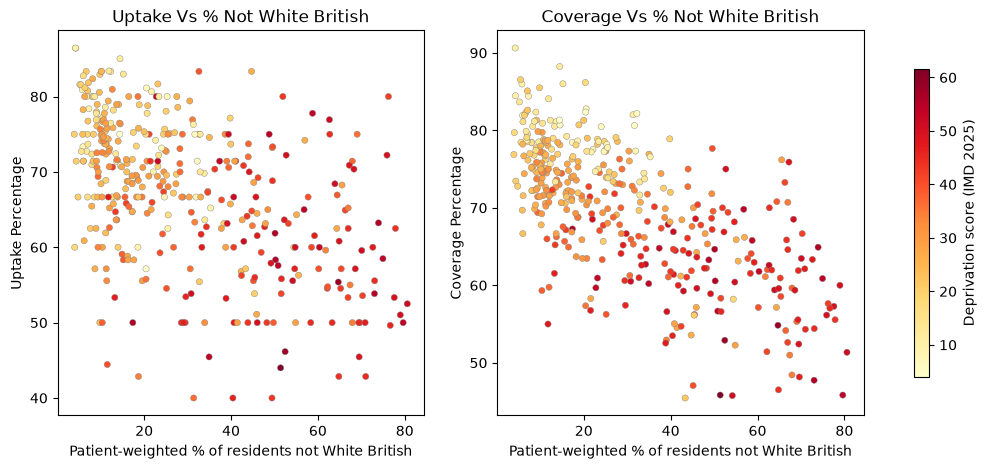

In [111]:
# rebuild plot_data: the old one was made before mean_non_white_pct existed
plot_data = gp_wise_data.loc[gp_wise_data["coverage_pct"] != 25]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

sc = axes[0].scatter(plot_data["mean_non_white_pct"], plot_data["uptake_pct"],
                     c=plot_data["depr_score"], cmap="YlOrRd", s=20, edgecolor="grey", linewidth=0.3)
axes[1].scatter(plot_data["mean_non_white_pct"], plot_data["coverage_pct"],
                c=plot_data["depr_score"], cmap="YlOrRd", s=20, edgecolor="grey", linewidth=0.3)

axes[0].set_ylabel("Uptake Percentage")
axes[0].set_title("Uptake Vs % Not White British")
axes[1].set_ylabel("Coverage Percentage")
axes[1].set_title("Coverage Vs % Not White British")

for ax in axes:
    ax.set_xlabel("Patient-weighted % of residents not White British")

fig.colorbar(sc, ax=axes, shrink=0.8, label="Deprivation score (IMD 2025)")

plt.savefig(Output_Directory/"uptake_coverage_vs_not_white_british.png", dpi=300, bbox_inches="tight")
plt.show()

In [112]:
uptake_eth = plot_data.dropna(subset=["uptake_pct", "mean_non_white_pct", "depr_score", "mean_dist_km"])
coverage_eth = plot_data.dropna(subset=["coverage_pct", "mean_non_white_pct", "depr_score", "mean_dist_km"])

eth_uptake = smf.ols("uptake_pct ~ mean_non_white_pct", data=uptake_eth).fit(cov_type="HC3")
print(eth_uptake.summary())

eth_coverage = smf.ols("coverage_pct ~ mean_non_white_pct", data=coverage_eth).fit(cov_type="HC3")
print(eth_coverage.summary())

                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.248
Model:                            OLS   Adj. R-squared:                  0.247
Method:                 Least Squares   F-statistic:                     122.1
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           7.06e-25
Time:                        12:34:53   Log-Likelihood:                -1389.4
No. Observations:                 391   AIC:                             2783.
Df Residuals:                     389   BIC:                             2791.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             74.3493      0

In [113]:
mr2_uptake = smf.ols("uptake_pct ~ depr_score + mean_non_white_pct", data=uptake_eth).fit(cov_type="HC3")
print(mr2_uptake.summary())

mr2_coverage = smf.ols("coverage_pct ~ depr_score + mean_non_white_pct", data=coverage_eth).fit(cov_type="HC3")
print(mr2_coverage.summary())

# collinearity check
print("Correlation:", coverage_eth[["depr_score", "mean_non_white_pct"]].corr().iloc[0, 1].round(2))

                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.321
Model:                            OLS   Adj. R-squared:                  0.318
Method:                 Least Squares   F-statistic:                     85.17
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.16e-31
Time:                        12:34:53   Log-Likelihood:                -1369.5
No. Observations:                 391   AIC:                             2745.
Df Residuals:                     388   BIC:                             2757.
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             79.5905      1

Ethnic composition was strongly associated with screening outcomes independently of deprivation. In models including both, uptake fell by 0.26 pp per unit of IMD score (95% CI −0.35 to −0.18) and 0.14 pp per percentage point of residents not White British (95% CI −0.19 to −0.08); coverage fell by 0.34 pp (−0.39 to −0.28) and 0.16 pp (−0.20 to −0.13) respectively (all p < 0.001). Adding ethnicity increased explained variance from 27% to 32% for uptake and from 52% to 62% for coverage. The two predictors were moderately correlated (r = 0.61; VIF ≈ 1.6), and each coefficient was attenuated by roughly one-third to two-fifths when the other was included, indicating substantial shared variation. Ethnic composition is likely a marker for factors such as language, health literacy and cultural acceptability of services, not a mechanism in itself; as practice-level associations, these results do not describe individual women’s behaviour.

In [114]:
# same practices for both: drop missing values in any variable used
uptake_full = plot_data.dropna(subset=["uptake_pct", "depr_score", "mean_non_white_pct", "mean_dist_km"])
coverage_full = plot_data.dropna(subset=["coverage_pct", "depr_score", "mean_non_white_pct", "mean_dist_km"])

# predictor correlations, to see the suppression directly
print(coverage_full[["depr_score", "mean_non_white_pct", "mean_dist_km"]].corr().round(2))

mr3_uptake = smf.ols("uptake_pct ~ depr_score + mean_non_white_pct + mean_dist_km",
                     data=uptake_full).fit(cov_type="HC3")
print(mr3_uptake.summary())

mr3_coverage = smf.ols("coverage_pct ~ depr_score + mean_non_white_pct + mean_dist_km",
                       data=coverage_full).fit(cov_type="HC3")
print(mr3_coverage.summary())

                    depr_score  mean_non_white_pct  mean_dist_km
depr_score                1.00                0.61         -0.30
mean_non_white_pct        0.61                1.00         -0.43
mean_dist_km             -0.30               -0.43          1.00
                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.338
Model:                            OLS   Adj. R-squared:                  0.333
Method:                 Least Squares   F-statistic:                     61.65
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.34e-32
Time:                        12:34:53   Log-Likelihood:                -1364.5
No. Observations:                 391   AIC:                             2737.
Df Residuals:                     387   BIC:                             2753.
Df Model:                           3                                         
Covariance Type:             

In [115]:
# drop the East Cheshire & Stockport practices
no_stockport = plot_data.loc[plot_data["service"] != "East Cheshire & Stockport BSS"]
print("Practices removed:", len(plot_data) - len(no_stockport))

# how much distance variation is left?
print(no_stockport["mean_dist_km"].describe())

uptake_ns = no_stockport.dropna(subset=["uptake_pct", "depr_score", "mean_non_white_pct", "mean_dist_km"])
coverage_ns = no_stockport.dropna(subset=["coverage_pct", "depr_score", "mean_non_white_pct", "mean_dist_km"])

mr3_uptake_ns = smf.ols("uptake_pct ~ depr_score + mean_non_white_pct + mean_dist_km",
                        data=uptake_ns).fit(cov_type="HC3")
print(mr3_uptake_ns.summary())

mr3_coverage_ns = smf.ols("coverage_pct ~ depr_score + mean_non_white_pct + mean_dist_km",
                          data=coverage_ns).fit(cov_type="HC3")
print(mr3_coverage_ns.summary())

Practices removed: 32
count    373.000000
mean       5.627320
std        3.356024
min        1.120226
25%        2.821088
50%        4.987799
75%        7.507174
max       16.699751
Name: mean_dist_km, dtype: float64
                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.339
Model:                            OLS   Adj. R-squared:                  0.334
Method:                 Least Squares   F-statistic:                     58.74
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           7.41e-31
Time:                        12:34:53   Log-Likelihood:                -1259.9
No. Observations:                 359   AIC:                             2528.
Df Residuals:                     355   BIC:                             2543.
Df Model:                           3                                         
Covariance Type:                  HC3                                   

After adjusting for deprivation and ethnic composition, greater distance to the nearest fixed site of the practice’s screening service was associated with lower uptake (−0.33 pp/km) and coverage (−0.31 pp/km). This association was masked in models without ethnicity (suppression: r = −0.43 between distance and % not White British) and persisted when Stockport practices, measured to a site outside Greater Manchester, were excluded.

In [116]:
uptake_fe = plot_data.dropna(subset=["uptake_pct", "depr_score", "mean_non_white_pct", "mean_dist_km", "service"])
coverage_fe = plot_data.dropna(subset=["coverage_pct", "depr_score", "mean_non_white_pct", "mean_dist_km", "service"])

fe_uptake = smf.ols("uptake_pct ~ depr_score + mean_non_white_pct + mean_dist_km + C(service)",
                    data=uptake_fe).fit(cov_type="HC3")
print(fe_uptake.summary())

fe_coverage = smf.ols("coverage_pct ~ depr_score + mean_non_white_pct + mean_dist_km + C(service)",
                      data=coverage_fe).fit(cov_type="HC3")
print(fe_coverage.summary())

                            OLS Regression Results                            
Dep. Variable:             uptake_pct   R-squared:                       0.351
Model:                            OLS   Adj. R-squared:                  0.341
Method:                 Least Squares   F-statistic:                     33.16
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.41e-32
Time:                        12:34:53   Log-Likelihood:                -1360.8
No. Observations:                 391   AIC:                             2736.
Df Residuals:                     384   BIC:                             2763.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                                                  coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------

After adjusting for deprivation and ethnic composition, greater patient-weighted distance to the nearest fixed site of the practice’s screening service was associated with lower uptake (−0.33 pp/km, 95% CI −0.54 to −0.13) and coverage (−0.31 pp/km, −0.43 to −0.19). The association was masked in models without ethnicity because practices with more residents not White British were closer to fixed sites (r = −0.43). It persisted when Stockport practices were excluded and when estimated within screening services using service fixed effects (uptake −0.51, coverage −0.42 pp/km). Distances are straight-line to fixed sites only; positive service effects for GMBSS (uptake) and East Cheshire & Stockport (coverage) may partly reflect mobile screening provision not captured by this measure.

In [117]:
# practice locations (British National Grid, metres)
geo = gp_points[["Area Code", "geometry"]].drop_duplicates("Area Code")

def residual_moran(model, data, k=8, seed=42):
    # residuals aligned to the practices used in the model
    res = data[["Area Code"]].copy()
    res["resid"] = model.resid
    g = geo.merge(res, on="Area Code", how="inner")

    # jitter by up to 1 m to break ties between practices sharing a postcode
    rng = np.random.default_rng(seed)
    g["geometry"] = gpd.points_from_xy(
        g.geometry.x + rng.uniform(-1, 1, len(g)),
        g.geometry.y + rng.uniform(-1, 1, len(g)),
        crs=geo.crs,
    )

    w = libpysal.weights.KNN.from_dataframe(g, k=k)
    w.transform = "r"   # row-standardise: each neighbour gets weight 1/k

    mi = Moran(g["resid"], w, permutations=999)
    return mi, g

for name, model, data in [("uptake", mr3_uptake, uptake_full),
                          ("coverage", mr3_coverage, coverage_full)]:
    mi, g = residual_moran(model, data)
    print(f"{name}: n = {len(g)}, Moran's I = {mi.I:.3f}, "
          f"expected = {mi.EI:.3f}, p (permutation) = {mi.p_sim:.3f}")

uptake: n = 391, Moran's I = 0.073, expected = -0.003, p (permutation) = 0.001
coverage: n = 404, Moran's I = 0.177, expected = -0.002, p (permutation) = 0.001


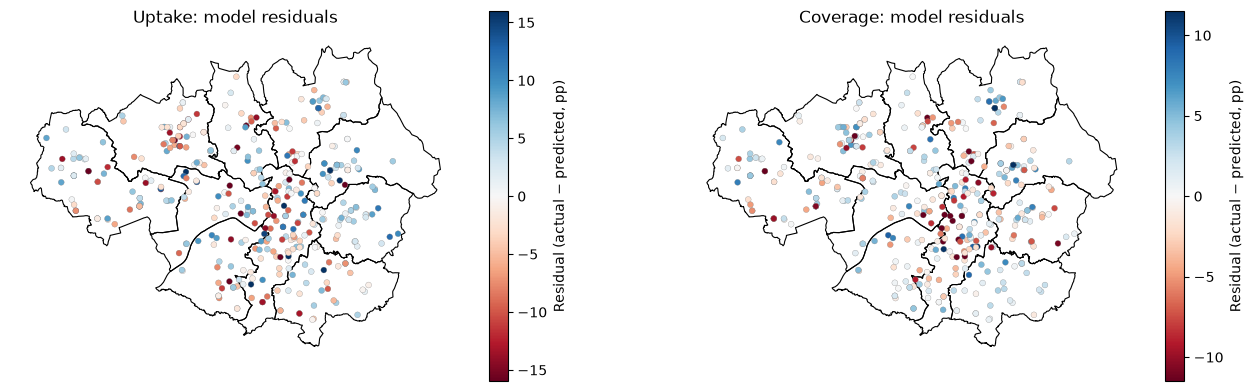

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, (name, model, data) in zip(axes, [("Uptake", mr3_uptake, uptake_full),
                                          ("Coverage", mr3_coverage, coverage_full)]):
    _, g = residual_moran(model, data)
    lim = g["resid"].abs().quantile(0.95)
    districts.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.8)
    g.plot(ax=ax, column="resid", cmap="RdBu", vmin=-lim, vmax=lim, markersize=18,
           edgecolor="grey", linewidth=0.2, legend=True,
           legend_kwds={"shrink": 0.6, "label": "Residual (actual − predicted, pp)"})
    ax.set_title(f"{name}: model residuals")
    ax.set_axis_off()

plt.savefig(Output_Directory / "residual_maps.png", dpi=300, bbox_inches="tight")
plt.show()

In [121]:
PREDICTORS = ["depr_score", "mean_non_white_pct", "mean_dist_km"]

def spatial_setup(data, k=8, seed=42):
    """Attach locations, jitter shared points, build KNN weights."""
    g = geo.merge(data, on="Area Code", how="inner")
    rng = np.random.default_rng(seed)
    g["geometry"] = gpd.points_from_xy(
        g.geometry.x + rng.uniform(-1, 1, len(g)),
        g.geometry.y + rng.uniform(-1, 1, len(g)),
        crs=geo.crs,
    )
    w = libpysal.weights.KNN.from_dataframe(g, k=k)
    w.transform = "r"
    return g, w

spatial_results = {}

for outcome, data in [("uptake_pct", uptake_full), ("coverage_pct", coverage_full)]:
    g, w = spatial_setup(data)
    y = g[[outcome]].values
    X = g[PREDICTORS].values

    # 1. OLS with spatial diagnostics (the LM tests)
    ols_sp = spreg.OLS(y, X, w=w, spat_diag=True, moran=True,
                       name_y=outcome, name_x=PREDICTORS, name_ds="GM practices")
    print(ols_sp.summary)

    # 2. Spatial error model, heteroskedasticity-robust
    err = spreg.GM_Error_Het(y, X, w=w, name_y=outcome, name_x=PREDICTORS,
                             name_ds="GM practices")
    print(err.summary)

    spatial_results[outcome] = {"ols": ols_sp, "error": err}

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :GM practices
Weights matrix      :     unknown
Dependent Variable  :  uptake_pct                Number of Observations:         391
Mean dependent var  :     67.2355                Number of Variables   :           4
S.D. dependent var  :      9.7624                Degrees of Freedom    :         387
R-squared           :      0.3382
Adjusted R-squared  :      0.3331
Sum squared residual:     24597.8                F-statistic           :     65.9262
Sigma-square        :      63.560                Prob(F-statistic)     :   1.873e-34
S.E. of regression  :       7.972                Log likelihood        :   -1364.508
Sigma-square ML     :      62.910                Akaike info criterion :    2737.016
S.E of regression ML:      7.9316                Schwarz criterion     :    2752.891

-----------------

Residuals from the OLS model showed significant positive spatial autocorrelation (Moran’s I: uptake 0.073, p = 0.007; coverage 0.177, p ≤ 0.001; k = 8 nearest-neighbour weights). Robust Lagrange Multiplier tests favoured a spatial error over a spatial lag specification for both outcomes, consistent with spatially clustered unmeasured factors and not with direct interaction between practices. In heteroskedasticity-robust spatial error models, deprivation (uptake −0.31, coverage −0.40 pp per IMD point), ethnic composition (−0.15, −0.17 pp per percentage point not White British) and distance (−0.31, −0.31 pp per km) all remained significant (p ≤ 0.015). The spatial error parameter was substantially larger for coverage (λ = 0.48) than for uptake (λ = 0.26), suggesting that unmeasured local factors, such as list inflation in high-turnover areas, play a greater role in coverage.

In [122]:
for outcome, data in [("uptake_pct", uptake_full), ("coverage_pct", coverage_full)]:
    g, w = spatial_setup(data)
    y = g[[outcome]].values
    X = g[PREDICTORS].values

    # maximum likelihood spatial error model (gives AIC)
    ml = spreg.ML_Error(y, X, w=w, name_y=outcome, name_x=PREDICTORS,
                        name_w="KNN k=8", name_ds="GM practices")
    print(ml.summary)

    # fit comparison
    ols_sp = spatial_results[outcome]["ols"]
    print(f"{outcome}: AIC  OLS = {ols_sp.aic:.1f}   spatial error (ML) = {ml.aic:.1f}")

    # did it remove the clustering? Moran's I on filtered residuals
    for label, model in [("GM_Error_Het", spatial_results[outcome]["error"]), ("ML_Error", ml)]:
        mi_after = Moran(model.e_filtered.flatten(), w, permutations=999)
        print(f"   {label} filtered residuals: Moran's I = {mi_after.I:.3f}, p = {mi_after.p_sim:.3f}")

    spatial_results[outcome]["ml_error"] = ml

C:\Users\Public\anaconda3\envs\autogis\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(
C:\Users\Public\anaconda3\envs\autogis\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :GM practices
Weights matrix      :     KNN k=8
Dependent Variable  :  uptake_pct                Number of Observations:         391
Mean dependent var  :     67.2355                Number of Variables   :           4
S.D. dependent var  :      9.7624                Degrees of Freedom    :         387
Pseudo R-squared    :      0.3369
Log likelihood      :  -1360.8268
Sigma-square ML     :     61.3210                Akaike info criterion :    2729.654
S.E of regression   :      7.8308                Schwarz criterion     :    2745.528

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
-----------------------------------------------------------------------------------